In [9]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

# =========修改你的学号========
STUDENT_ID = 20244080321
# =============================

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[机器指纹] {MACHINE_FP}")
print(f"[学号] {STUDENT_ID}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] None
[机器指纹] 5c9a6f22bf8d43e1
[学号] 20244080321
[RUN_ID] 20244080321-5c9a6f22bf8d43e1


In [10]:
# 设置随机种子，保证结果可复现
np.random.seed(42)

# --------1. 不同类型ndarray，对比Python list--------
arr_int = np.array([1,2,3,4], dtype=int)
arr_float = np.array([1.1,2.2,3.3], dtype=float)
arr_bool = np.array([True, False, True])

print("===整数数组===")
print(f"dtype:{arr_int.dtype}, shape:{arr_int.shape}, ndim:{arr_int.ndim}")
print("===浮点数数组===")
print(f"dtype:{arr_float.dtype}, shape:{arr_float.shape}, ndim:{arr_float.ndim}")
print("===布尔数组===")
print(f"dtype:{arr_bool.dtype}, shape:{arr_bool.shape}, ndim:{arr_bool.ndim}")

# --------2 arange(12)改变形状--------
a1 = np.arange(12)
print("\n原始一维数组", a1)

a_34 = a1.reshape(3,4)
print("\nreshape(3,4):\n", a_34)

a_232 = a1.reshape(2,3,2)
print("\nreshape(2,3,2):\n", a_232)

# --------3 (3,4)数组索引--------
print("\n===索引操作===")
arr = np.arange(12).reshape(3,4)
print("原数组：\n",arr)

row2 = arr[1, :]   # 第2行（numpy从0开始计数）
print("取第2行：", row2, "shape", row2.shape)

col1_3 = arr[:, 0:3] # 第1~3列
print("取第1‑3列：\n", col1_3, "shape", col1_3.shape)

gt6 = arr[arr>6]
print("大于6的元素：", gt6, "shape", gt6.shape)

# --------4 布尔条件索引--------
x = np.arange(10)
cond1 = (x < 2) | (x >7)
res1 = x[cond1]
print("\n小于2或大于7：", res1)

cond2 = (x>3) & (x<7)
res2 = x[cond2]
print("大于3且小于7：", res2)

# --------5 逐元素乘法 vs 矩阵乘法--------
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])
print("\nA:\n",A,"\nB:\n",B)

elem_mul1 = A * B
elem_mul2 = np.multiply(A,B)
mat_mul1 = A @ B
mat_mul2 = np.matmul(A,B)

print("\n逐元素乘法 A*B：\n", elem_mul1)
print("np.multiply：\n", elem_mul2)
print("矩阵乘法 @：\n", mat_mul1)
print("np.matmul：\n", mat_mul2)


===整数数组===
dtype:int64, shape:(4,), ndim:1
===浮点数数组===
dtype:float64, shape:(3,), ndim:1
===布尔数组===
dtype:bool, shape:(3,), ndim:1

原始一维数组 [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

===索引操作===
原数组：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
取第2行： [4 5 6 7] shape (4,)
取第1‑3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape (3, 3)
大于6的元素： [ 7  8  9 10 11] shape (5,)

小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]

A:
 [[1 2]
 [3 4]] 
B:
 [[5 6]
 [7 8]]

逐元素乘法 A*B：
 [[ 5 12]
 [21 32]]
np.multiply：
 [[ 5 12]
 [21 32]]
矩阵乘法 @：
 [[19 22]
 [43 50]]
np.matmul：
 [[19 22]
 [43 50]]


实验 1 小结：NumPy 数组

本次实验学习 NumPy 库，练习 ndarray 数组的基础创建、索引与运算操作。

1、ndarray 数组里全部元素必须是同一种数据类型，而普通 Python 列表能够存放不同类型的数据。

2、ndarray 在内存中连续存放，计算速度更快，支持向量化运算。

3、reshape 用来修改数组的形状，但数组元素的总数量不能改变。例如 12 个元素，可以调整成 (3,4) 二维数组，或是 (2,3,2) 三维数组。

4、NumPy 的下标从 0 开始。布尔索引可以根据条件筛选数组元素，|代表逻辑或，&代表逻辑与，写条件表达式的时候每个条件都要加上括号，不然容易报错。

5、*和np.multiply()是逐元素相乘，只把对应位置的元素相乘；@和np.matmul()是矩阵乘法，需要遵守矩阵相乘的维度要求。

但是写数组运算代码时，要分清逐元素乘法和矩阵乘法，两种写法得到的结果完全不一样，一不小心就会出错。

In [11]:
np.random.seed(42)

#1 模拟成绩，均值70，标准差10，1000个
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, a_min=0, a_max=100)

print("====模拟成绩统计====")
print(f"样本数:{len(scores)}")
print(f"最小值:{np.min(scores):.2f}")
print(f"最大值:{np.max(scores):.2f}")
print(f"均值:{np.mean(scores):.2f}")
print(f"标准差:{np.std(scores):.2f}")
print(f"极差:{np.max(scores)-np.min(scores):.2f}")

#2 不放回抽样
pop = np.arange(1,11)
print("\n原始总体", pop)
# 均匀不放回抽5个
sample_uniform = np.random.choice(pop, size=5, replace=False)
print("均匀不放回抽样：", sample_uniform)
# 按数值大小加权抽样
weights = pop / np.sum(pop)
sample_weighted = np.random.choice(pop, size=5, replace=False, p=weights)
print("按数值加权抽样：", sample_weighted)

#3 permutation(不修改原数组) vs shuffle(原地修改)
arr_orig = np.array([1,2,3,4,5])
arr_perm = np.random.permutation(arr_orig)
print("\npermutation:")
print("原数组", arr_orig)
print("返回打乱副本", arr_perm)

arr_shuf = np.array([1,2,3,4,5])
np.random.shuffle(arr_shuf)
print("\nshuffle原地打乱:")
print("打乱后数组", arr_shuf)

#4 设置nan缺失值
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan   #第10、20、30个（下标从0）
nan_count = np.sum(np.isnan(scores_nan))

mean_normal = np.mean(scores_nan)      #普通mean遇到nan输出nan
mean_nan_ign = np.nanmean(scores_nan)  #忽略nan求均值

print("\n====缺失值实验====")
print(f"缺失值数量：{nan_count}")
print(f"普通np.mean(含nan): {mean_normal}")
print(f"np.nanmean忽略缺失值均值：{mean_nan_ign:.2f}")

#5 内存表格，留给实验4使用，不写入磁盘
idx_arr = np.arange(len(scores_nan))
exp2_table = {"index": idx_arr, "score": scores_nan}


====模拟成绩统计====
样本数:1000
最小值:37.59
最大值:100.00
均值:70.18
标准差:9.76
极差:62.41

原始总体 [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样： [ 4  9  2  6 10]
按数值加权抽样： [10  2  8  9  6]

permutation:
原数组 [1 2 3 4 5]
返回打乱副本 [5 1 3 2 4]

shuffle原地打乱:
打乱后数组 [1 5 2 4 3]

====缺失值实验====
缺失值数量：3
普通np.mean(含nan): nan
np.nanmean忽略缺失值均值：70.20


# 实验 2 小结：随机抽样与缺失值

本次实验练习 NumPy 的随机抽样操作，同时学习如何处理数据里的缺失值。

1. `np.random.normal`可以生成服从正态分布的样本数据，搭配`np.clip`能够限制数值的范围，在生成成绩数据时，用来把数值约束在 0~100 之间，避免出现不合理分数。
2. `np.random.choice`用来完成抽样。参数`replace=False`代表不放回抽样；参数 p 可以自定义每个元素被抽取到的概率，实现加权抽样。
3. `permutation`会返回打乱顺序后的新数组，原始数组不会发生改变；而`np.random.shuffle`是原地打乱，会直接修改原来的数组，使用的时候要留意两者区别。
4. `np.nan`用来表示缺失值。普通的`np.mean`计算均值时，如果数组里存在 nan，最终结果会直接变成 nan。这时就要用`np.nanmean`，它可以自动跳过缺失值，正常完成统计计算。
5. 实验体会：处理带缺失值的数据时，不能直接使用常规统计函数，要选择 nan 系列函数，不然计算结果会失效。

====线性方程组求解====
方程组解 x=2.29, y=0.43

====方程 x2-4=0 求根====
方程根：2.00

====求 f(x,y)=x2+y2 的极小值====
极小值点 x=-0.00, y=-0.00
极小值 = 0.00

====独立样本t检验====
t统计量：-2.398, p值：0.0197
p<0.05，两组均值存在显著差异


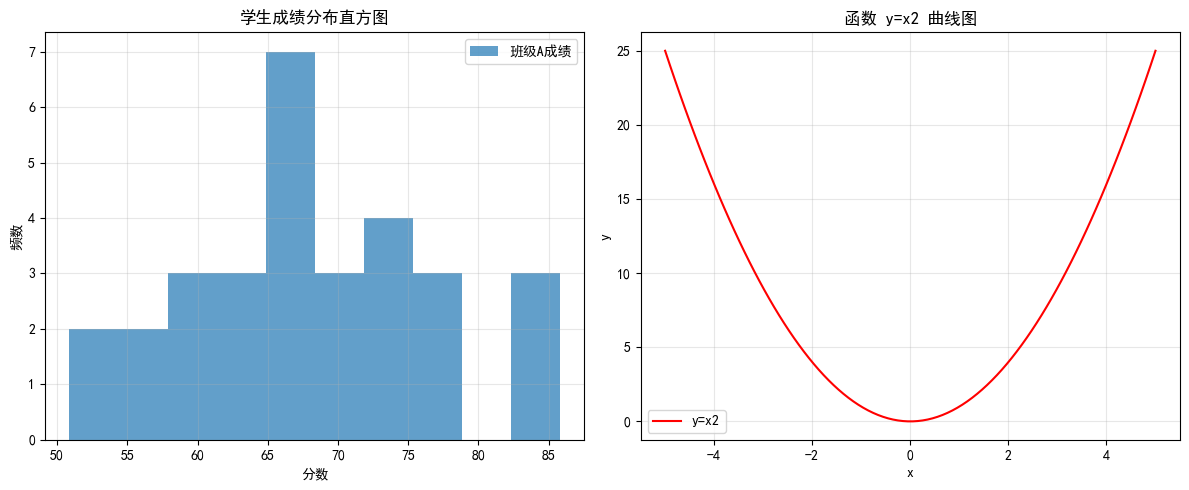

In [12]:
from scipy.optimize import fsolve
from scipy.optimize import minimize
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np

# 设置图片中文显示
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

## -------- 1. 解线性方程组 --------
# 方程组：
# 2x + y = 5
# x - 3y = 1
A = np.array([[2, 1], [1, -3]])
b = np.array([5, 1])
x_solve = np.linalg.solve(A, b)
print("====线性方程组求解====")
print(f"方程组解 x={x_solve[0]:.2f}, y={x_solve[1]:.2f}")

## -------- 2. 方程求根 fsolve --------
def f(x):
    return x**2 - 4
root = fsolve(f, x0=1)
print("\n====方程 x2-4=0 求根====")
print(f"方程根：{root[0]:.2f}")

## --------3. 函数最小值求解 minimize --------
def fun_min(x):
    return x[0]**2 + x[1]**2
res_min = minimize(fun_min, x0=[2, 2])
print("\n====求 f(x,y)=x2+y2 的极小值====")
print(f"极小值点 x={res_min.x[0]:.2f}, y={res_min.x[1]:.2f}")
print(f"极小值 = {res_min.fun:.2f}")

## --------4. 假设检验 t检验 --------
np.random.seed(42)
data1 = np.random.normal(loc=70, scale=10, size=30)
data2 = np.random.normal(loc=75, scale=10, size=30)
t_stat, p_value = stats.ttest_ind(data1, data2)
print("\n====独立样本t检验====")
print(f"t统计量：{t_stat:.3f}, p值：{p_value:.4f}")
if p_value < 0.05:
    print("p<0.05，两组均值存在显著差异")
else:
    print("p>=0.05，两组均值无显著差异")

## --------5 Matplotlib绘图：直方图+函数曲线 --------
plt.figure(figsize=(12,5))
# 子图1：成绩直方图
plt.subplot(1,2,1)
plt.hist(data1, bins=10, alpha=0.7, label="班级A成绩")
plt.xlabel("分数")
plt.ylabel("频数")
plt.title("学生成绩分布直方图")
plt.legend()
plt.grid(alpha=0.3)
#子图2：y=x2函数曲线
plt.subplot(1,2,2)
x_line = np.linspace(-5,5,100)
y_line = x_line ** 2
plt.plot(x_line, y_line, color="red", label="y=x2")
plt.xlabel("x")
plt.ylabel("y")
plt.title("函数 y=x2 曲线图")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 实验3小结：SciPy 数值计算与 Matplotlib 可视化

本次实验借助 SciPy 库完成多种数值计算，并用 Matplotlib 实现数据可视化。

1. SciPy 库能够实现线性方程组求解、非线性方程求根、函数极小值计算，还可以做统计学假设检验。
2. fsolve 用于求解非线性方程，但它属于局部寻根方法，**找到的根受初始猜测值 x0 影响**。一开始我设置 x0=1，只能算出靠近 1 的根 2.00，漏掉了 - 2；想要得到全部根，需要设置多个不同的初始猜测值。minimize 用来求解函数最小值；stats.ttest_ind 实现独立样本 t 检验，当 p<0.05 时，代表两组数据均值存在显著差异。
3. 使用 Matplotlib 绘图时，需要配置 plt.rcParams，解决中文显示方框乱码的问题。subplot 可以在一张画布上划分多个子图，绘图时一般要添加标题、坐标轴标签和图例，方便看图理解。
4. plt.hist () 用来绘制直方图，适合观察数据分布；plt.plot () 用来绘制连续的函数曲线。
5. 注意点：绘图时如果使用特殊上标字符，会出现 Glyph 字体警告，但是换成普通数字写法就能消除警告

In [13]:
import pandas as pd

# 1. 创建DataFrame，行索引设为姓名，计算总分Total、平均分Average
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")  # 将Name设置为行索引

# 新增总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("=====1. DataFrame信息=====")
print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())

# 2. loc、iloc读取Carol记录；筛选平均分≥80学生
print("\n=====2. loc、iloc读取Carol记录=====")
print("loc按名字索引：")
print(df.loc["Carol"])
# 找到Carol所在的行号
carol_idx = df.index.get_loc("Carol")
print("\niloc按位置索引：")
print(df.iloc[carol_idx])

print("\n平均分不低于80的学生：")
high_avg_stu = df[df["Average"] >= 80]
print(high_avg_stu)

#3 axis=0 列均值；axis=1 每行学生均值
print("\n=====3. mean(axis=0)各科列均值=====")
col_mean = df[["Math","English","Python"]].mean(axis=0)
print(col_mean)
print("\nmean(axis=1)每个学生行均值：")
row_mean = df[["Math","English","Python"]].mean(axis=1)
print(row_mean)

#4 apply求单科最高分；agg一次性求每科最小、均值、最大；rank排名
print("\n=====4 apply、agg、rank=====")
df["MaxScore"] = df[["Math","English","Python"]].apply(max, axis=1)
print("每人三科最高分：")
print(df["MaxScore"])

agg_result = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\n每科 min mean max：")
print(agg_result)

df["Math_rank"] = df["Math"].rank(ascending=False) # 数学成绩降序排名
print("\n数学成绩排名：")
print(df[["Math","Math_rank"]])

#5 按Group分组，统计人数、三科平均分；transform增加组内Python平均分
print("\n=====5 groupby分组+transform=====")
group_stat = df.groupby("Group").agg(人数=("Group","count"),
                                     数学平均分=("Math","mean"),
                                     英语平均分=("English","mean"),
                                     Python平均分=("Python","mean"))
print(group_stat)

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组内Python平均分列，全部数据：")
print(df)

#6 filter：保留Python平均分>=80的组
print("\n=====6 filter筛选组=====")
def filter_func(group):
    return group["Python"].mean() >= 80

group_filtered = df.groupby("Group").filter(filter_func)
print("Python组平均分≥80的学生：")
print(group_filtered)

#7 协方差矩阵、皮尔逊相关系数矩阵
print("\n=====7 协方差、相关系数矩阵=====")
sub_df = df[["Math","English","Python"]]
cov_matrix = sub_df.cov()
corr_matrix = sub_df.corr()
print("协方差矩阵：")
print(cov_matrix)
print("\n皮尔逊相关系数矩阵：")
print(corr_matrix)


=====1. DataFrame信息=====
行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

=====2. loc、iloc读

# 实验 4 小结：Pandas DataFrame 操作

这次实验练习了 Pandas 中 DataFrame 的常用操作，熟悉表格数据处理的基本方法。

1. 使用`set_index()`可以设置行索引，也能够直接对现有列进行运算，生成总分 Total、平均分 Average 这类新的数据列。
2. `loc`和`iloc`用来提取表格数据，`loc`依靠索引名称选取内容，`iloc`按数字位置获取；搭配布尔表达式，就能筛选出满足条件的数据记录。
3. `mean()`求平均值，`axis=0`是按列计算均值，`axis=1`是按行计算均值，处理成绩表时经常用到。
4. `apply()`可以给每一行数据执行自定义函数；`agg()`支持一次性完成多种聚合统计；`rank()`可以对成绩进行排名。
5. `groupby()`实现分组统计；`transform()`能把分组后的计算结果匹配回原表格的每一行；`filter()`可以筛选保留符合条件的分组。
6. `cov()`生成协方差矩阵，协方差大于 0 代表两组数据同向变化；`corr()`计算皮尔逊相关系数，取值范围 [-1,1]，数值越接近 1，代表变量之间线性相关性越强。本次实验中数学、英语、Python 三科成绩相关系数都偏高，成绩变化趋势比较接近。

不过当输出的矩阵内容较多时，Jupyter 会自动截断显示，点击text editor就可以完整查看表格